# Proyek Klasifikasi Gambar: [Input Nama Dataset]
- **Nama:** [MiftahStudent]
- **Email:** [miftahstudent78@gmail.com]
- **ID Dicoding:** [Miftah Student]

## Import Semua Packages/Library yang Digunakan

In [28]:
# Library untuk manipulasi file
import os
import shutil
import zipfile
import pathlib
from pathlib import Path
from shutil import copyfile

# Library untuk manipulasi data
import numpy as np
import pandas as pd

# Library untuk visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

# Library tambahan
import random
from random import sample
from tqdm.notebook import tqdm as tq

In [2]:
# Library pemrosesan data gambar
import cv2
from PIL import Image

# Library skimage
import skimage
from skimage import io
from skimage.transform import resize
from skimage.transform import rotate, AffineTransform, warp
from skimage import img_as_ubyte
from skimage.exposure import adjust_gamma
from skimage.util import random_noise

In [3]:
# Library pengembangan model
import keras
import tensorflow as tf

# Library untuk pembagian dataset dan evaluasi model
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

# Library dari Keras
from keras import layers, models

# Library untuk preprocessing gambar
from tensorflow.keras.preprocessing import image
from tensorflow.keras.preprocessing.image import ImageDataGenerator, img_to_array, load_img

# Library untuk optimasi
from tensorflow.keras.optimizers import Adam, RMSprop, SGD

# Library untuk arsitektur jaringan saraf
from tensorflow.keras.layers import (
    InputLayer, Conv2D, SeparableConv2D, MaxPooling2D, MaxPool2D,
    Dense, Flatten, Dropout, BatchNormalization
)
from tensorflow.keras import regularizers
from tensorflow.keras.models import Sequential, Model

# Library untuk model pra-terlatih
from tensorflow.keras.applications import MobileNet
from tensorflow.keras.applications.densenet import DenseNet121

# Library untuk utilitas dan callbacks
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import ModelCheckpoint, Callback, EarlyStopping, ReduceLROnPlateau

In [4]:
# Library Penanganan Warning
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In [5]:
# Mencetak versi TensorFlow yang sedang digunakan
print(tf.__version__)

2.18.0


## Data Preparation

### Data Loading

In [6]:
# Upload file dengan google colab
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"jonathan898","key":"5f3e73ab1abdfdee091a23cc427b45fa"}'}

In [7]:
# Buat direktori .kaggle di HOME
os.makedirs("/root/.kaggle", exist_ok=True)

# Pindahkan kaggle.json ke lokasi yang benar
shutil.move("/content/kaggle.json", "/root/.kaggle/kaggle.json")

# Pastikan izin file sudah benar
os.chmod("/root/.kaggle/kaggle.json", 600)

In [8]:
# Download dataset dari kaggle
!kaggle datasets download -d antobenedetti/animals

Dataset URL: https://www.kaggle.com/datasets/antobenedetti/animals
License(s): GPL-2.0


In [9]:
# Ekstrak dataset yang didownload
!unzip animals.zip

Streaming output truncated to the last 5000 lines.
  inflating: animals/train/horse/horse2690.jpg  
  inflating: animals/train/horse/horse2691.jpg  
  inflating: animals/train/horse/horse2692.jpg  
  inflating: animals/train/horse/horse2693.jpg  
  inflating: animals/train/horse/horse2694.jpg  
  inflating: animals/train/horse/horse2695.jpg  
  inflating: animals/train/horse/horse2696.jpg  
  inflating: animals/train/horse/horse2697.jpg  
  inflating: animals/train/horse/horse2698.jpg  
  inflating: animals/train/horse/horse2699.jpg  
  inflating: animals/train/horse/horse27.jpg  
  inflating: animals/train/horse/horse270.jpg  
  inflating: animals/train/horse/horse2701.jpg  
  inflating: animals/train/horse/horse2702.jpg  
  inflating: animals/train/horse/horse2703.jpg  
  inflating: animals/train/horse/horse2704.jpg  
  inflating: animals/train/horse/horse2705.jpg  
  inflating: animals/train/horse/horse2706.jpg  
  inflating: animals/train/horse/horse2707.jpg  
  inflating: animals/

In [10]:
from google.colab import drive
drive.mount('/content/drive/')

Mounted at /content/drive/


In [11]:
# Direktori utama untuk data pelatihan dan pengujian
train_direct = "animals/train"
test_direct  = "animals/val"

# Direktori hasil penggabungan data pelatihan dan pengujian
join_dir = "animals/dataset"

In [12]:
# Membuat direktori untuk menyimpan data gabungan jika belum ada
os.makedirs(join_dir, exist_ok=True)

In [13]:
# Mengubah nama file dalam direktori validasi dengan menambahkan prefix '000_'
for category in os.listdir(test_direct):
    category_dir = os.path.join(test_direct, category)
    # Loop melalui semua file dalam folder
    for filename in os.listdir(category_dir):
        # Tentukan path file lama
        old_file_path = os.path.join(category_dir, filename)

        # Tentukan nama file baru (misalnya, menambahkan prefix '000_')
        new_filename = '000_' + filename
        new_file_path = os.path.join(category_dir, new_filename)

        # Ganti nama file
        os.rename(old_file_path, new_file_path)

print('Semua file dalam folder berhasil diganti namanya.')

Semua file dalam folder berhasil diganti namanya.


Menyalin file dan folder dataset dari direktori pelatihan dan pengujian ke dalam direktori gabungan yang telah dibuat.

In [14]:
# Menyalin file dan folder dari direktori train ke direktori gabungan
for category in os.listdir(train_direct):
    category_dir = os.path.join(train_direct, category)
    if os.path.isdir(category_dir):
        shutil.copytree(category_dir, os.path.join(join_dir, category), dirs_exist_ok=True)

# Menyalin file dan folder dari direktori test ke direktori gabungan
for category in os.listdir(test_direct):
    category_dir = os.path.join(test_direct, category)
    if os.path.isdir(category_dir):
        shutil.copytree(category_dir, os.path.join(join_dir, category), dirs_exist_ok=True)

In [15]:
# Menghitung jumlah file dalam setiap kategori dan total dalam direktori dataset
folder_path = join_dir
sum_num_files = 0
for category in os.listdir(folder_path):
    category_dir = os.path.join(folder_path, category)
    num_files = len(os.listdir(category_dir))
    print(f'Jumlah file dalam folder "{category_dir}" adalah: {num_files}')
    sum_num_files = sum_num_files + num_files
print(f'Total jumlah file dalam folder "{folder_path}" adalah: {sum_num_files}')

Jumlah file dalam folder "animals/dataset/dog" adalah: 2927
Jumlah file dalam folder "animals/dataset/elephant" adalah: 3029
Jumlah file dalam folder "animals/dataset/lion" adalah: 2973
Jumlah file dalam folder "animals/dataset/horse" adalah: 3005
Jumlah file dalam folder "animals/dataset/cat" adalah: 3037
Total jumlah file dalam folder "animals/dataset" adalah: 14971


### Data Preprocessing

Menampilkan 5 gambar secara acak dari setiap kelas dalam data pelatihan.

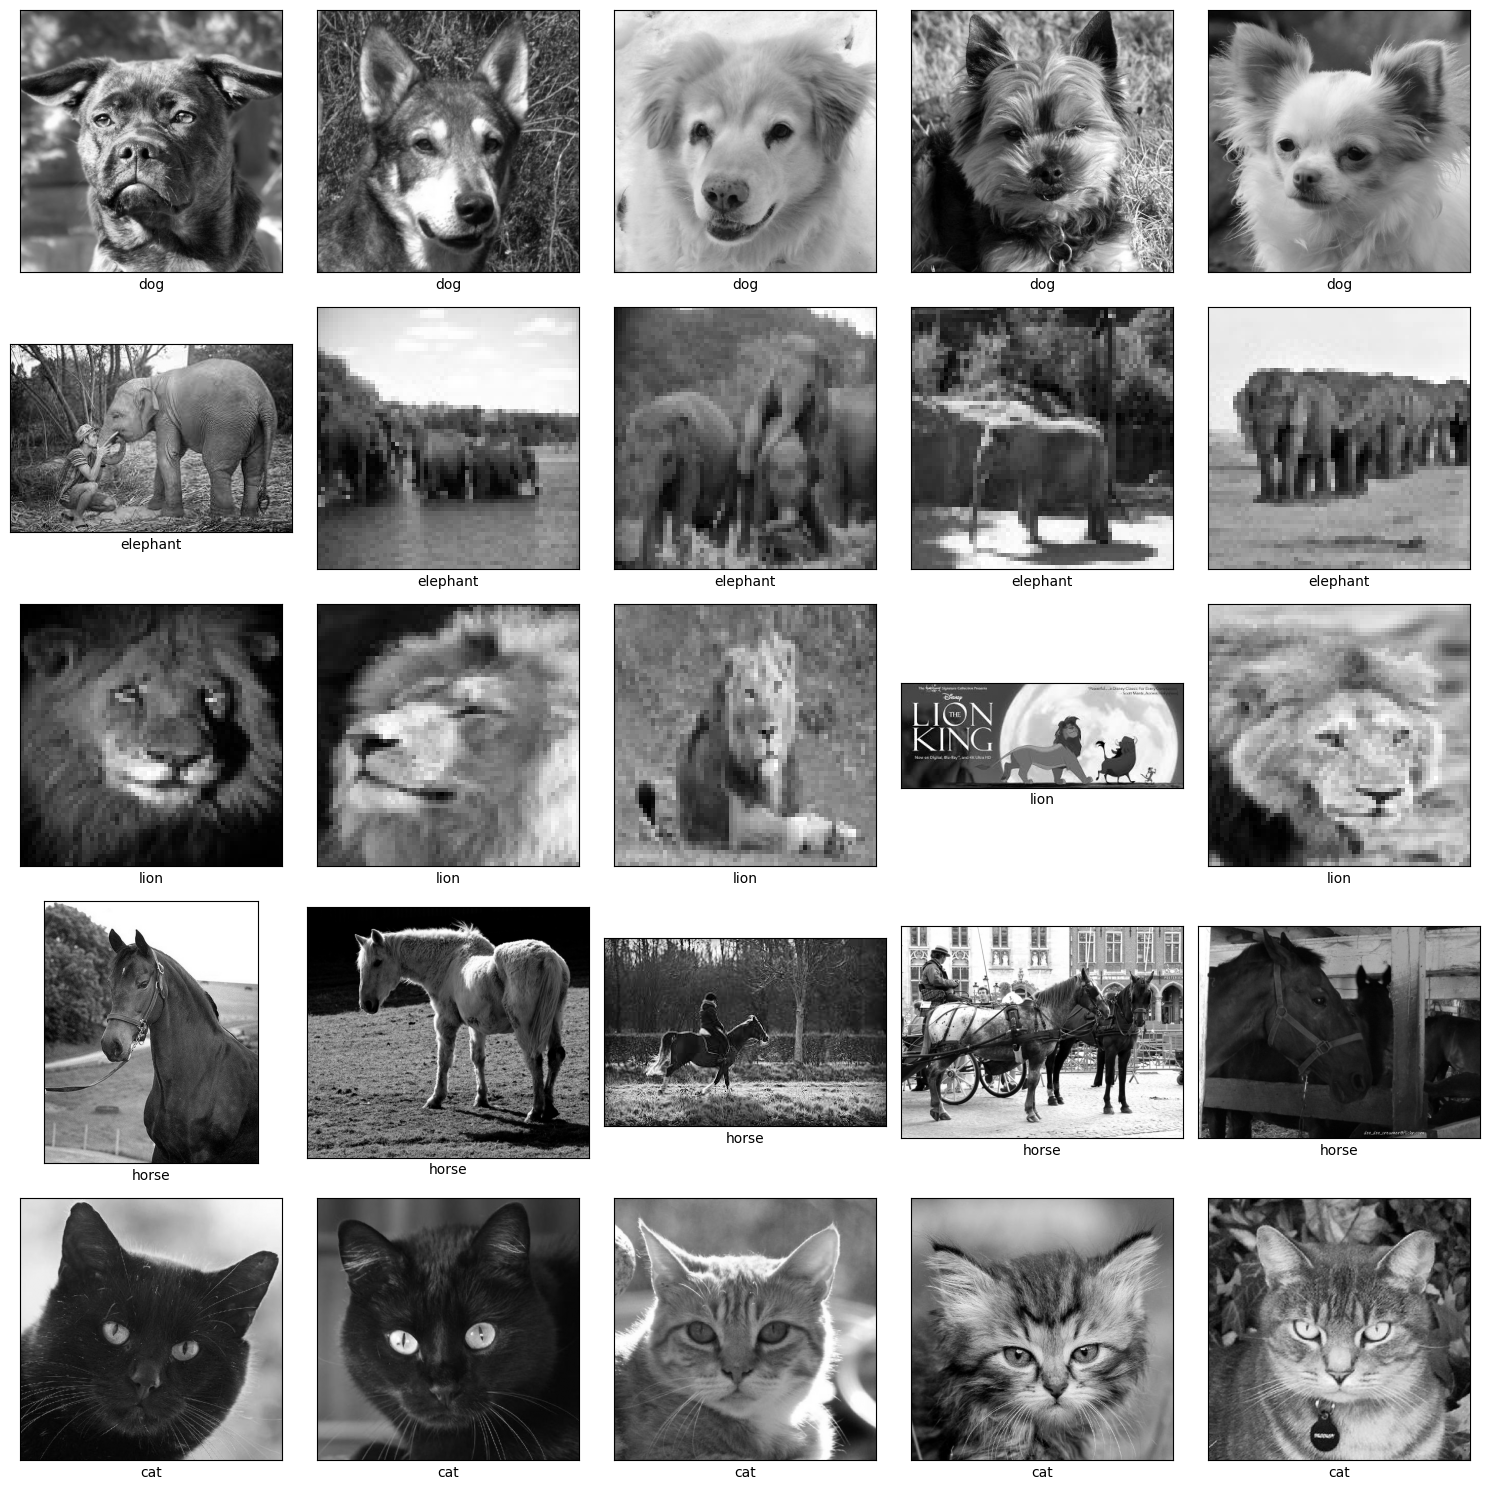

In [16]:
# Membuat kamus untuk menyimpan daftar gambar dari setiap kelas dalam dataset
lung_image = {}

# Menentukan path sumber untuk data latih
path = "animals/"
path_sub = os.path.join(path, "dataset")
for i in os.listdir(path_sub):
    lung_image[i] = os.listdir(os.path.join(path_sub, i))

# Menampilkan 5 gambar secara acak dari masing-masing kelas dalam dataset
# Gambar yang ditampilkan akan berbeda setiap kali kode dijalankan
path_sub = "animals/dataset/"

# Menampilkan gambar secara acak dari setiap kelas dalam data latih
fig, axs = plt.subplots(len(lung_image.keys()), 5, figsize=(15, 15))

for i, class_name in enumerate(os.listdir(path_sub)):
    images = np.random.choice(lung_image[class_name], 5, replace=False)

    for j, image_name in enumerate(images):
        img_path = os.path.join(path_sub, class_name, image_name)
        img = Image.open(img_path).convert("L")  # Konversi ke skala keabuan
        axs[i, j].imshow(img, cmap='gray')
        axs[i, j].set(xlabel=class_name, xticks=[], yticks=[])

fig.tight_layout()

Memvisualisasikan distribusi data dalam dataset.

In [17]:
def plot_distribution():
    # Menentukan path sumber dataset
    source_path = "animals/dataset/"

    # Membuat daftar untuk menyimpan nama file, path file, dan label
    file_name = []
    labels = []
    full_path = []

    # Mengumpulkan informasi file dan label dari dataset
    for path, subdirs, files in os.walk(source_path):
        for name in files:
            full_path.append(os.path.join(path, name))
            labels.append(path.split('/')[-1])
            file_name.append(name)

    distribution_train = pd.DataFrame({"path": full_path, 'file_name': file_name, "Animals": labels})

    # Memvisualisasikan distribusi jumlah gambar dalam setiap kelas
    animal_name = distribution_train['Animals']
    plt.figure(figsize=(6,6))
    plt.title('Distribusi Hewan dalam Dataset')
    sns.set_style("whitegrid")  # Menggunakan tema grid putih
    sns.set_palette("husl")  # Menggunakan palet warna husl
    sns.set_context("notebook")
    plot_data = sns.countplot(animal_name)

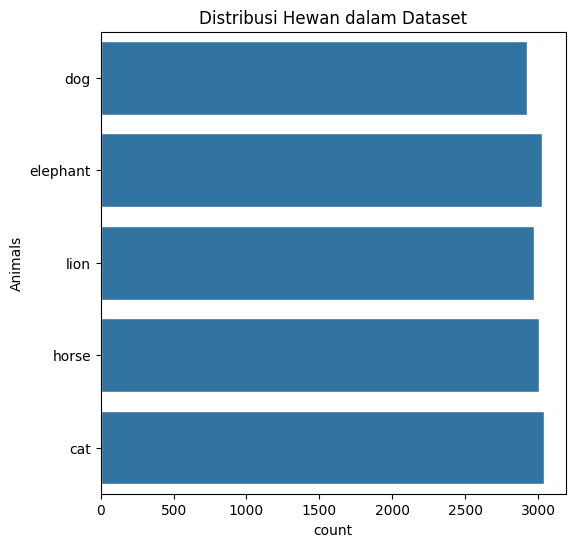

In [18]:
plot_distribution()

Proses augmentasi dataset.

In [19]:
# Fungsi untuk melakukan rotasi berlawanan arah jarum jam
def anticlockwise_rotation(animal_image):
    animal_image = cv2.cvtColor(animal_image, 0)
    animal_image = cv2.resize(animal_image, (224,224))
    sudut = random.randint(0,180)
    return rotate(animal_image, sudut)
# Fungsi untuk melakukan rotasi searah jarum jam
def clockwise_rotation(animal_image):
    animal_image = cv2.cvtColor(animal_image, 0)
    animal_image = cv2.resize(animal_image, (224,224))
    sudut = random.randint(0,180)
    return rotate(animal_image, -sudut)
# Fungsi untuk menerapkan rotasi acak pada gambar
def random_rotation(animal_image, angle_range=(-20, 20)):
    angle = np.random.uniform(angle_range[0], angle_range[1])
    h, w = animal_image.shape[:2]
    center = (w // 2, h // 2)
    rotation_matrix = cv2.getRotationMatrix2D(center, angle, 1.0)
    rotated_image = cv2.warpAffine(animal_image, rotation_matrix, (w, h), flags=cv2.INTER_LINEAR)
    return rotated_image
# Fungsi untuk membalik gambar secara vertikal
def flip_up_down(animal_image):
    animal_image = cv2.cvtColor(animal_image, 0)
    animal_image = cv2.resize(animal_image, (224,224))
    return np.flipud(animal_image)
# Fungsi untuk meningkatkan kecerahan gambar
def add_brightness(animal_image):
    animal_image = cv2.cvtColor(animal_image, 0)
    animal_image = cv2.resize(animal_image, (224,224))
    animal_image = adjust_gamma(animal_image, gamma=0.5, gain=1)
    return animal_image
# Fungsi untuk menerapkan efek blur pada gambar
def blur_image(animal_image):
    animal_image = cv2.cvtColor(animal_image, 0)
    animal_image = cv2.resize(animal_image, (224,224))
    return cv2.GaussianBlur(animal_image, (9,9),0)
# Fungsi untuk memberikan efek pergeseran atau shear pada gambar
def sheared(animal_image):
    animal_image = cv2.cvtColor(animal_image, 0)
    animal_image = cv2.resize(animal_image, (224,224))
    transform = AffineTransform(shear=0.2)
    shear_image = warp(animal_image, transform, mode="wrap")
    return shear_image
# Fungsi untuk menerapkan pergeseran gambar dalam arah tertentu (warp shift)
def warp_shift(animal_image):
    animal_image = cv2.cvtColor(animal_image, 0)
    animal_image = cv2.resize(animal_image, (224,224))
    transform = AffineTransform(translation=(0,40))
    warp_image = warp(animal_image, transform, mode="wrap")
    return warp_image

In [20]:
# Menyimpan semua metode pra-pemrosesan dalam variabel transformasi
transformations = { 'rotate anticlockwise': anticlockwise_rotation,'rotate clockwise': clockwise_rotation,'random rotation' : random_rotation,'warp shift': warp_shift,'blurring image': blur_image,'add brightness' : add_brightness,'flip up down': flip_up_down,'shear image': sheared}

images=[] # List untuk menyimpan gambar setelah melalui proses augmentasi

# Menentukan jumlah augmentasi untuk setiap kategori gambar
for x in range(2):
  if (x == 0):
    images_path = join_dir + "/lion"
    augmented_path = join_dir + "/lion"
    images_to_generate = 30
  if (x == 1):
    images_path = join_dir + "/dog"
    augmented_path = join_dir + "/dog"
    images_to_generate = 80

  # Membaca nama gambar dalam folder dan menyimpannya dalam array "images"
  for im in os.listdir(images_path):
      images.append(os.path.join(images_path, im))
  i = 1

  # Melakukan augmentasi hingga jumlah gambar yang diinginkan tercapai
  while i <= images_to_generate:
      image = random.choice(images)
      try:
          original_image = io.imread(image)
          transformed_image = None
          n = 0  # Variabel untuk menghitung jumlah transformasi yang diterapkan
          transformation_count = random.randint(1, len(transformations)) # Memilih jumlah transformasi secara acak

          # Menerapkan sejumlah transformasi yang dipilih secara acak
          while n <= transformation_count:
              key = random.choice(list(transformations)) # Memilih metode augmentasi secara acak
              transformed_image = transformations[key](original_image)
              n = n + 1

          # Menyimpan gambar hasil augmentasi dengan nama baru
          new_image_path = "%s/augmented_image_%s.jpg" % (augmented_path, i)
          transformed_image = img_as_ubyte(transformed_image)  # Mengonversi gambar ke format byte dengan rentang nilai [0, 255]
          cv2.imwrite(new_image_path, transformed_image)  # Menyimpan gambar yang telah diproses
          i = i + 1
      except ValueError as e:
          print('Gagal membaca gambar', image, ':', e, 'melewati gambar ini.')

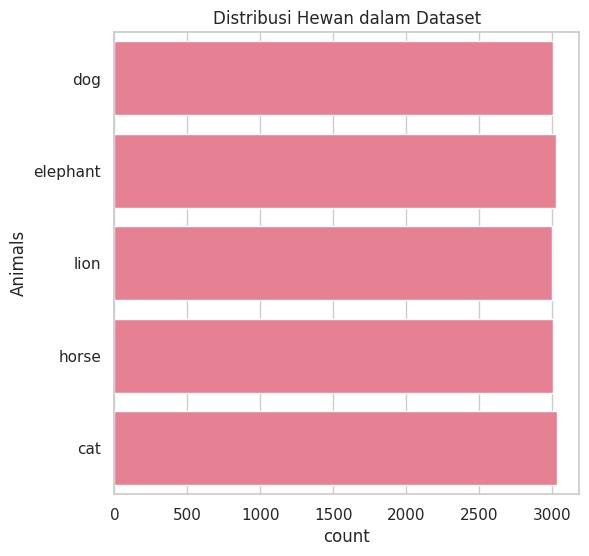

In [21]:
plot_distribution()

#### Split Dataset

In [22]:
# Menentukan folder utama yang berisi dataset gambar
mypath = "animals/dataset/"

file_name = []
labels = []
full_path = []

# Menelusuri setiap file dalam folder dataset dan menyimpannya dalam daftar
for path, subdirs, files in os.walk(mypath):
    for name in files:
        full_path.append(os.path.join(path, name))
        labels.append(path.split('/')[-1])
        file_name.append(name)

# Mengonversi data yang telah dikumpulkan menjadi dataframe agar lebih terstruktur
df = pd.DataFrame({"path": full_path, 'file_name': file_name, "animals-label": labels})

# Menampilkan jumlah gambar dalam setiap kategori hewan
df.groupby(['animals-label']).size()

,0
animals-label,
cat,3037
dog,3007
elephant,3029
horse,3005
lion,3003


In [23]:
# Menentukan variabel untuk pemisahan data, di mana:
# X berisi path gambar, dan y berisi label gambar

X = df['path']
y = df['animals-label']
# Membagi dataset menjadi data latih (train) dan data uji (test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=300)

In [24]:
# Menggabungkan data latih dan data uji ke dalam masing-masing dataframe
df_tr = pd.DataFrame({'path': X_train, 'animals-label': y_train, 'set': 'train'})  # Data latih
df_te = pd.DataFrame({'path': X_test, 'animals-label': y_test, 'set': 'val'})  # Data uji

In [25]:
# Menggabungkan DataFrame df_tr dan df_te menjadi satu
df_all = pd.concat([df_tr, df_te], ignore_index=True)

# Menampilkan jumlah data dalam setiap kategori berdasarkan set (train/val)
print(df_all.groupby(['set', 'animals-label']).size(), '\n')

# Menampilkan 5 sampel data secara acak
print(df_all.sample(5))

# Menentukan direktori sumber dataset asli yang berisi semua gambar
datasource_path = "animals/dataset/"

# Menentukan direktori penyimpanan dataset setelah proses pembagian train dan test
dataset_path = "/content/drive/MyDrive/ml_menengah/dataset-final/"

set    animals-label
train  cat              2403
       dog              2422
       elephant         2462
       horse            2397
       lion             2380
val    cat               634
       dog               585
       elephant          567
       horse             608
       lion              623
dtype: int64 

                                      path animals-label    set
3380    animals/dataset/horse/horse962.jpg         horse  train
1330   animals/dataset/horse/horse2125.jpg         horse  train
11517    animals/dataset/lion/lion1862.jpg          lion  train
1917        animals/dataset/cat/cat965.jpg           cat  train
8508       animals/dataset/cat/cat2191.jpg           cat  train


In [29]:
for index, row in tq(df_all.iterrows()):
    # Menentukan path file asli
    file_path = row['path']
    if not os.path.exists(file_path):
        file_path = os.path.join(datasource_path, row['animals-label'], row['image'].split('.')[0])

    # Membuat folder tujuan jika belum ada
    target_dir = os.path.join(dataset_path, row['set'], row['animals-label'])
    if not os.path.exists(target_dir):
        os.makedirs(target_dir)

    # Menentukan nama file tujuan
    destination_file_name = file_path.split('/')[-1]
    file_dest = os.path.join(target_dir, destination_file_name)

    # Menyalin file ke direktori tujuan jika belum ada
    if not os.path.exists(file_dest):
        shutil.copy2(file_path, file_dest)

0it [00:00, ?it/s]

In [30]:
# Menentukan variabel `mypath` sebagai lokasi dataset gambar
mypath = '/content/drive/MyDrive/ml_menengah/dataset-final/val'

# Inisialisasi list untuk menyimpan informasi file
file_name = []
labels = []
full_path = []

# Mengakses semua file dalam folder dataset dan menyimpan informasi terkait
for path, subdirs, files in os.walk(mypath):
    for name in files:
        full_path.append(os.path.join(path, name))  # Menyimpan path lengkap file
        labels.append(path.split('/')[-1])  # Menyimpan label berdasarkan nama folder
        file_name.append(name)  # Menyimpan nama file

# Membuat DataFrame untuk menyusun informasi dataset secara lebih terstruktur
df = pd.DataFrame({"path": full_path, 'file_name': file_name, "animals-label": labels})

# Menampilkan jumlah gambar dalam setiap kategori hewan
df.groupby(['animals-label']).size()

,0
animals-label,
cat,634
dog,585
elephant,567
horse,608
lion,623


In [31]:
# Tentukan lokasi direktori untuk data latih dan uji
folder_path_train = '/content/drive/MyDrive/ml_menengah/dataset-final/train'
folder_path_test = '/content/drive/MyDrive/ml_menengah/dataset-final/val'

# Hitung total gambar dalam setiap kategori di folder train
sum_num_files = 0
for category_dir_two in os.listdir(folder_path_train):
  category_dir = os.path.join(folder_path_train, category_dir_two)
  num_files = len(os.listdir(category_dir))
  print(f'Total gambar dalam folder "{category_dir}" adalah: {num_files}')
  sum_num_files += num_files
print(f'Total gambar dalam direktori "{folder_path_train}" adalah: {sum_num_files}')

# Hitung total gambar dalam setiap kategori di folder test
sum_num_files = 0
for category_dir_one in os.listdir(folder_path_test):
    category_dir = os.path.join(folder_path_test, category_dir_one)
    num_files = len(os.listdir(category_dir))
    print(f'Total gambar dalam folder "{category_dir}" adalah: {num_files}')
    sum_num_files += num_files
print(f'Total gambar dalam direktori "{folder_path_test}" adalah: {sum_num_files}')

Total gambar dalam folder "/content/drive/MyDrive/ml_menengah/dataset-final/train/horse" adalah: 2397
Total gambar dalam folder "/content/drive/MyDrive/ml_menengah/dataset-final/train/dog" adalah: 2422
Total gambar dalam folder "/content/drive/MyDrive/ml_menengah/dataset-final/train/lion" adalah: 2380
Total gambar dalam folder "/content/drive/MyDrive/ml_menengah/dataset-final/train/elephant" adalah: 2462
Total gambar dalam folder "/content/drive/MyDrive/ml_menengah/dataset-final/train/cat" adalah: 2403
Total gambar dalam direktori "/content/drive/MyDrive/ml_menengah/dataset-final/train" adalah: 12064
Total gambar dalam folder "/content/drive/MyDrive/ml_menengah/dataset-final/val/dog" adalah: 585
Total gambar dalam folder "/content/drive/MyDrive/ml_menengah/dataset-final/val/horse" adalah: 608
Total gambar dalam folder "/content/drive/MyDrive/ml_menengah/dataset-final/val/lion" adalah: 623
Total gambar dalam folder "/content/drive/MyDrive/ml_menengah/dataset-final/val/elephant" adalah: 

In [32]:
# Setup ImageDataGenerator
train_val_generator = ImageDataGenerator(
    rescale=1./255,
    rotation_range=7,
    zoom_range=0.2,
    horizontal_flip=True,
    validation_split=0.2  # Memisahkan 20% data untuk validasi
)

test_generator = ImageDataGenerator(
    rescale=1./255
)

train_images = train_val_generator.flow_from_directory(
    folder_path_train,
    target_size=(64, 64),
    batch_size=64,
    class_mode='categorical',
    subset='training',
    shuffle=True
)

val_images = train_val_generator.flow_from_directory(
    folder_path_train,
    target_size=(64, 64),
    batch_size=64,
    class_mode='categorical',
    subset='validation',
    shuffle=True
)

test_images = test_generator.flow_from_directory(
    folder_path_test,
    target_size=(64, 64),
    batch_size=64,
    class_mode='categorical',
    shuffle=False
)

Found 9653 images belonging to 5 classes.
Found 2411 images belonging to 5 classes.
Found 3017 images belonging to 5 classes.


## Modelling

In [33]:
# Membuat Model CNN
model = models.Sequential([
    layers.Conv2D(32, (3,3), activation='relu', input_shape=(64,64,3), kernel_regularizer=regularizers.l2(0.01)),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(64, (3,3), activation='relu', kernel_regularizer=regularizers.l2(0.01)),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(128, (3,3), activation='relu', kernel_regularizer=regularizers.l2(0.01)),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(256, (3,3), activation='relu', kernel_regularizer=regularizers.l2(0.01)),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2,2),

    layers.Flatten(),

    layers.Dense(1024, activation='relu', kernel_regularizer=regularizers.l2(0.01)),
    layers.Dense(512, activation='relu', kernel_regularizer=regularizers.l2(0.01)),
    layers.Dense(256, activation='relu', kernel_regularizer=regularizers.l2(0.01)),

    layers.Dense(5, activation='softmax')
])

/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [34]:
# setup learning rate dan early stopping
reduce_lr = ReduceLROnPlateau(monitor='val_accuracy', factor=0.5, patience=2, min_lr=1e-6, verbose=1)
early_stopping = EarlyStopping(monitor="val_loss", mode='min', min_delta=0.1, patience=10, restore_best_weights=True)

# Determine Optimizer & Loss Function
model.compile(optimizer=tf.optimizers.Adam(), loss='categorical_crossentropy', metrics=['accuracy'])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 62, 62, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 62, 62, 32)          │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 31, 31, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 29, 29, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 29, 29, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 14, 14, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 12, 12, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 12, 12, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 6, 6, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 4, 4, 256)           │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_3                │ (None, 4, 4, 256)           │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 2, 2, 256)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 1024)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 1024)                │       1,049,600 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 512)                 │         524,800 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 256)                 │         131,328 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 5)                   │           1,285 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,097,349 (8.00 MB)

 Trainable params: 2,096,389 (8.00 MB)

 Non-trainable params: 960 (3.75 KB)

In [35]:
# Train model
history = model.fit(train_images, validation_data=val_images, epochs=30, callbacks=[early_stopping,reduce_lr], verbose=1)

/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/30
151/151 ━━━━━━━━━━━━━━━━━━━━ 216s 1s/step - accuracy: 0.5297 - loss: 16.0439 - val_accuracy: 0.1974 - val_loss: 4.5239 - learning_rate: 0.0010
Epoch 2/30
151/151 ━━━━━━━━━━━━━━━━━━━━ 264s 1s/step - accuracy: 0.7436 - loss: 2.4829 - val_accuracy: 0.1974 - val_loss: 3.0481 - learning_rate: 0.0010
Epoch 3/30
151/151 ━━━━━━━━━━━━━━━━━━━━ 195s 1s/step - accuracy: 0.7815 - loss: 1.3589 - val_accuracy: 0.4720 - val_loss: 1.8924 - learning_rate: 0.0010
Epoch 4/30
151/151 ━━━━━━━━━━━━━━━━━━━━ 193s 1s/step - accuracy: 0.7989 - loss: 1.1189 - val_accuracy: 0.6089 - val_loss: 1.4813 - learning_rate: 0.0010
Epoch 5/30
151/151 ━━━━━━━━━━━━━━━━━━━━ 192s 1s/step - accuracy: 0.8255 - loss: 0.9901 - val_accuracy: 0.7453 - val_loss: 1.1485 - learning_rate: 0.0010
Epoch 6/30
151/151 ━━━━━━━━━━━━━━━━━━━━ 192s 1s/step - accuracy: 0.8215 - loss: 0.9563 - val_accuracy: 0.7599 - val_loss: 1.0956 - learning_rate: 0.0010
Epoch 7/30
151/151 ━━━━━━━━━━━━━━━━━━━━ 209s 1s/step - accuracy: 0.8267 - loss: 0

## Evaluasi dan Visualisasi

In [36]:
# Evaluasi model pada validation set
val_loss, val_acc = model.evaluate(val_images)
print(f'Validation Accuracy: {val_acc*100:.2f}%')

# Evaluasi model pada test set
test_loss, test_acc = model.evaluate(test_images)
print(f'Test Accuracy: {test_acc*100:.2f}%')

38/38 ━━━━━━━━━━━━━━━━━━━━ 27s 710ms/step - accuracy: 0.9057 - loss: 0.5722
Validation Accuracy: 89.96%
48/48 ━━━━━━━━━━━━━━━━━━━━ 26s 547ms/step - accuracy: 0.9517 - loss: 0.4109
Test Accuracy: 90.52%


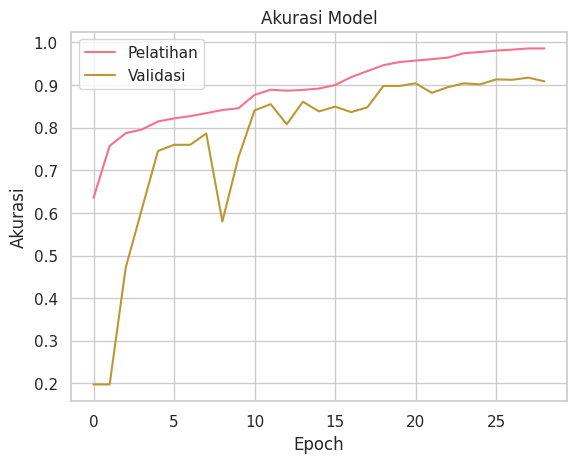

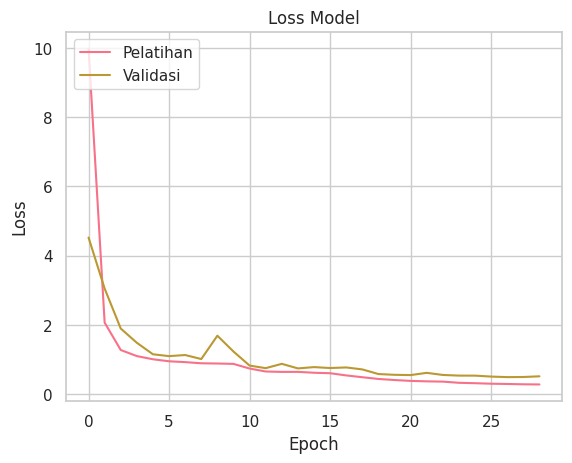

In [37]:
# Menampilkan grafik akurasi pada data pelatihan dan validasi
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Akurasi Model')
plt.ylabel('Akurasi')
plt.xlabel('Epoch')
plt.legend(['Pelatihan', 'Validasi'], loc='upper left')
plt.show()

# Menampilkan grafik loss pada data pelatihan dan validasi
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Loss Model')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Pelatihan', 'Validasi'], loc='upper left')
plt.show()

## Konversi Model

In [38]:
base_path = "/content/drive/MyDrive/ml_menengah/submission"

# Buat direktori untuk setiap format model jika belum ada
folders = ["tfjs_model", "tflite", "saved_model"]
for folder in folders:
    os.makedirs(os.path.join(base_path, folder), exist_ok=True)

In [39]:
saved_model_path = os.path.join(base_path, "saved_model")
tf.saved_model.save(model, saved_model_path)

In [40]:
model_h5_path = os.path.join(base_path, "cnn_image_classification.h5")
model.save(model_h5_path)

In [41]:
tflite_model_path = os.path.join(base_path, "tflite/model.tflite")

# Konversi ke TFLite
converter = tf.lite.TFLiteConverter.from_saved_model(saved_model_path)
tflite_model = converter.convert()

# Simpan model dalam folder yang sesuai
with open(tflite_model_path, "wb") as f:
    f.write(tflite_model)

In [42]:
labels = ["class1", "class2", "class3"]  # Sesuaikan dengan label sebenarnya
label_path = os.path.join(base_path, "tflite/label.txt")

with open(label_path, "w") as f:
    for label in labels:
        f.write(label + "\n")

In [43]:
!pip install tensorflowjs
!tensorflowjs_converter --input_format=keras {model_h5_path} {os.path.join(base_path, "tfjs_model")}

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.1/89.1 kB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.0/53.0 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.1/16.1 MB 47.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 644.9/644.9 MB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 36.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.7/4.7 MB 44.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 28.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 46.3 MB/s eta 0:00:00
  Attempting uninstall: packaging
    Found existing installation: packaging 24.2
    Uninstalling packaging-24.2:
      Successfully uninstalled packaging-24.2
  Attempting uninstall: ml_dtypes
    Found existing installation: ml-dtypes 0.4.1
    Uninstalling ml-dtypes-0.4.1:
      Successfully uninstalled ml-dtypes-0.4.1
  Attempting uninstall: tensorboard
    Found exis

2025-03-27 17:21:32.411836: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1743096092.437955   31050 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1743096092.445933   31050 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1743096092.468381   31050 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1743096092.468432   31050 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1743096092.468437   31050 computation_placer.cc:177] computation placer alr

## Inference (Optional)

In [44]:
!pip freeze > requirements.txt